In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import json
import xarray as xr
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import dask
from dask.diagnostics import ProgressBar

import sys

sys.path.append("../..")

from src.conversion_energy.aggregate_data import (
    aggregate_data_per_country,
)

from src.utils.utils_xarray import sel_extent

from src.utils.constants import EXTENT_CH, REFERENCE_PERIOD, EXTENT_BC

sns.set_style("whitegrid", {"grid.color": ".93"})

In [4]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_data_temporary = Path(paths["path_data_temporary"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [5]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

In [6]:
dask.config.set(num_workers=15, threads_per_worker=16)
dask.config.set(
    {
        "distributed.worker.memory.target": 0.7,  # Spill to disk at 70%
        "distributed.worker.memory.spill": 0.8,  # Start spilling at 80%
        "distributed.worker.memory.pause": 0.9,  # Pause worker at 90%
        "array.chunk-size": "512MiB",
        "logging.distributed": "error",  # Less verbose logs
    }
)

# Bias corrected

## Temperature

In [6]:
ds_tas_yearly = {}
ds_tas_ref = {}
for path in (path_data_processed / "cordex_processed").glob(
    "*rcp85/bias_corrected/3hr/tas.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)
    print(climate_model_chain, climate_scenario)
    ds_tas = sel_extent(
        xr.open_zarr(
            path,
            chunks="auto",
        ),
        extent=EXTENT_CH,
    )
    with ProgressBar():
        ds_tas_yearly[f"{climate_model_chain}_{climate_scenario}"] = (
            ds_tas.resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])
        )
        ds_tas_ref[f"{climate_model_chain}_{climate_scenario}"] = (
            ds_tas_yearly[f"{climate_model_chain}_{climate_scenario}"]
            .sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
            .mean(dim="time")
            .compute()
        )

CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 rcp85
[########################################] | 100% Completed | 65.24 s
CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1 rcp85
[########################################] | 100% Completed | 18.83 s
CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1 rcp85
[########################################] | 100% Completed | 6.40 ss
CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1 rcp85
[########################################] | 100% Completed | 6.28 ss
MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1 rcp85
[########################################] | 100% Completed | 13.14 s
MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 rcp85
[########################################] | 100% Completed | 5.98 ss
MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1 rcp85
[########################################] | 100% Completed | 6.50 ss
MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1 rcp85
[########################################] | 100% Completed | 8.42 ss


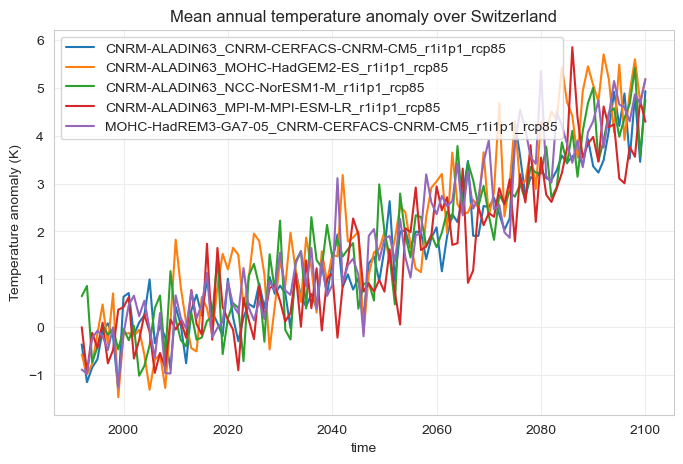

In [84]:
fig, ax = plt.subplots(figsize=(8, 5))
for climate_model_chain_scenario in ds_tas_yearly.keys():
    to_plot = (
        ds_tas_yearly[climate_model_chain_scenario]["tas"].sel(time=slice(None, "2099"))
        - ds_tas_ref[climate_model_chain_scenario]["tas"]
    )

    to_plot.plot(
        ax=ax,
        label=climate_model_chain_scenario,
    )
ax.set_title("Mean annual temperature anomaly over Switzerland")
ax.set_ylabel("Temperature anomaly (K)")
ax.legend()
plt.show()

In [108]:
# compute 20-year window means centered on each decade center (2030, 2040, ..., 2090)
centers = list(range(2030, 2100, 10))

decade_means = {}
for climate_model_chain_scenario in ds_tas_yearly.keys():
    ds_tas_yearly_model = ds_tas_yearly[climate_model_chain_scenario]
    decade_means_climate_model = []
    for c in centers:
        start = c - 14
        end = c + 15
        da = (
            ds_tas_yearly_model["tas"]
            .sel(time=slice(str(start), str(end)))
            .mean(dim="time")
        )
        da = da.expand_dims(decade_center=[c])
        decade_means_climate_model.append(da)

    decade_means_climate_model = xr.concat(
        decade_means_climate_model, dim="decade_center"
    ).compute()
    decade_means[climate_model_chain_scenario] = decade_means_climate_model

In [109]:
# combine yearly 'tas' from all model-chain-scenario combos into a pandas DataFrame
# then compute the median across models for each year (time index)
series_list = []
for key, ds in decade_means.items():
    s = ds.to_series() - ds_tas_ref[key]["tas"].item()
    s.name = key
    series_list.append(s)

df_decadal = pd.concat(series_list, axis=1)  # index = time, columns = models
median_per_year = df_decadal.median(axis=1, skipna=True)  # pandas Series indexed by time
median_per_year

decade_center
2030    0.839417
2040    1.281250
2050    1.837219
2060    2.249268
2070    2.793274
2080    3.384674
2090    3.890137
dtype: float32

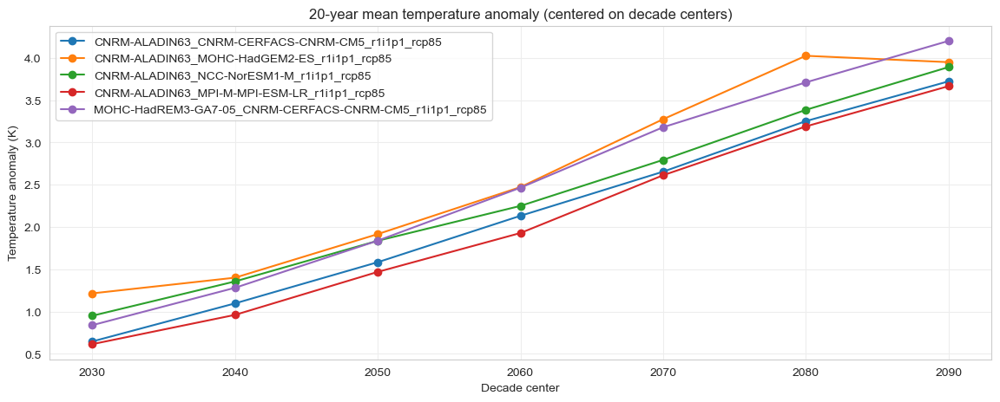

In [110]:
fig, ax = plt.subplots(figsize=(14, 5))

for climate_model_chain_scenario in ds_tas_yearly.keys():
    da = decade_means[climate_model_chain_scenario]  # DataArray with coord 'decade_center'
    ref = ds_tas_ref[climate_model_chain_scenario]["tas"]  # scalar reference mean
    anomaly = (da - ref).compute()  # compute dask array

    ax.plot(
        anomaly["decade_center"].values,
        anomaly.values,
        marker="o",
        label=climate_model_chain_scenario,
    )

ax.set_xticks(centers)
ax.set_xlabel("Decade center")
ax.set_ylabel("Temperature anomaly (K)")
ax.set_title("20-year mean temperature anomaly (centered on decade centers)")
ax.legend()
plt.show()

## Precipitation

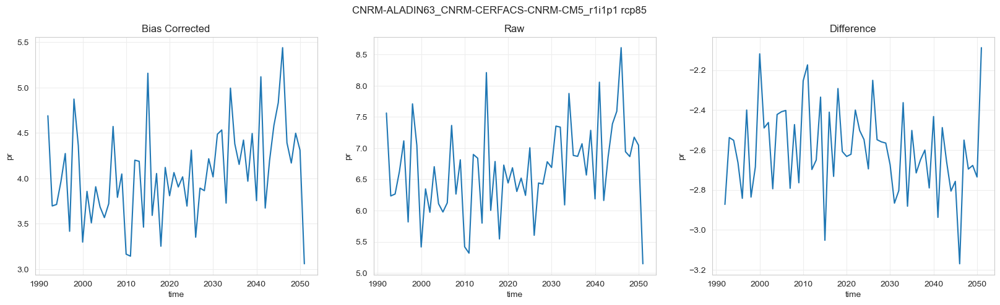

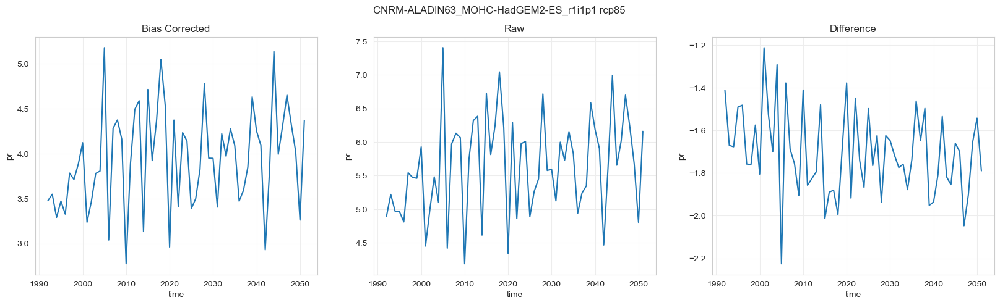

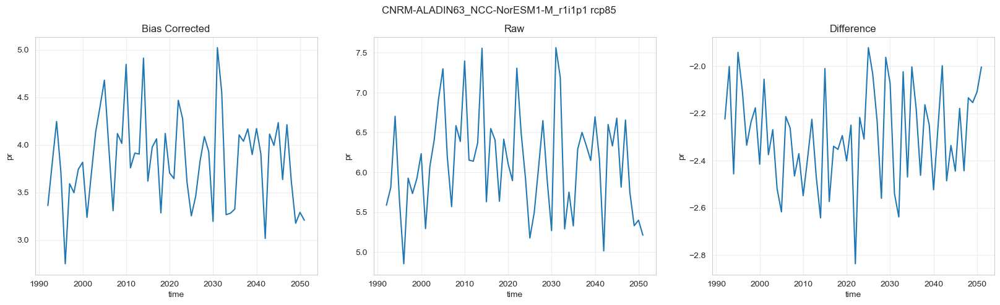

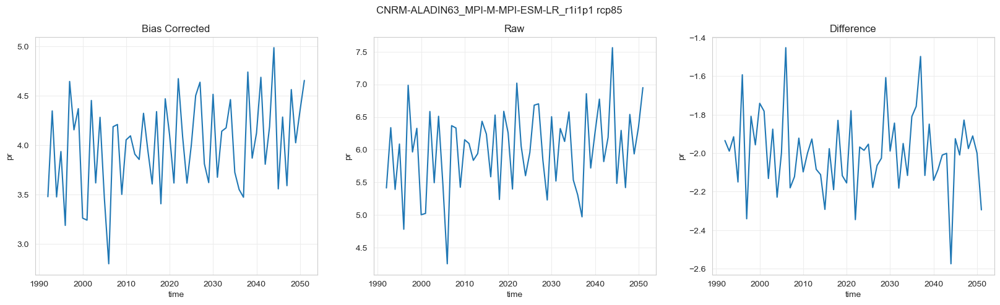

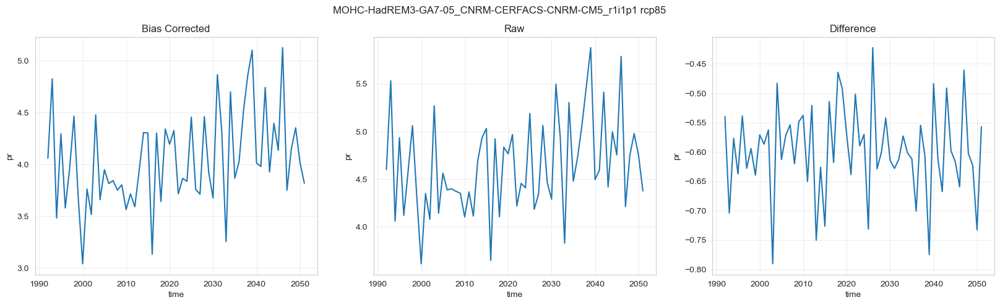

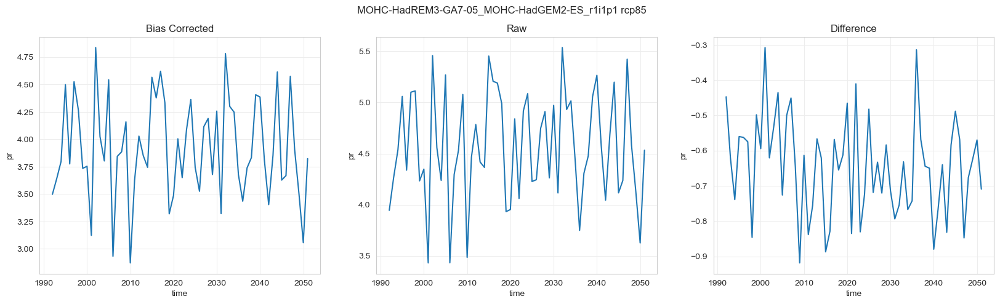

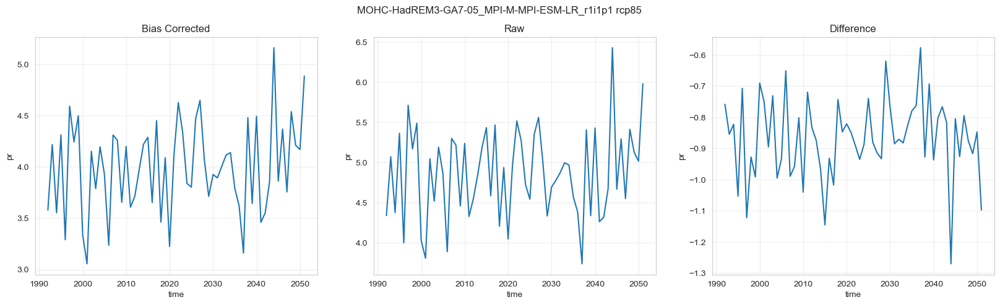

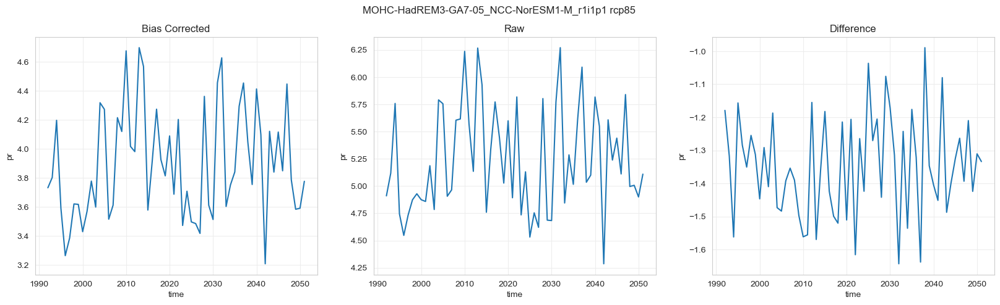

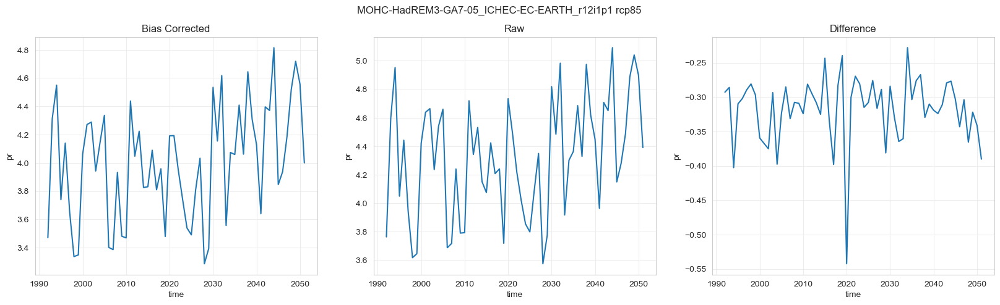

In [ ]:
for path in (path_data_processed / "cordex_processed").glob(
    "*/bias_corrected/day/pr.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)

    ds_pr_bs = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "day" / "pr.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).pr.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])

    ds_pr_raw = (sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / "day" / "pr.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).pr.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])) * 86400

    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f"{climate_model_chain} {climate_scenario}")
    ds_pr_bs.plot(ax=ax[0])
    ax[0].set_title("Bias Corrected")
    ds_pr_raw.plot(ax=ax[1])
    ax[1].set_title("Raw")
    (ds_pr_bs - ds_pr_raw).plot(ax=ax[2])
    ax[2].set_title("Difference")
    plt.show()

In [20]:
ds_precip_yearly = {}
ds_precip_monthly = {}
ds_precip_ref_yearly = {}
ds_precip_ref_monthly = {}
for path in (path_data_processed / "cordex_processed").glob(
    "*rcp85/bias_corrected/day/pr.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)
    print(climate_model_chain, climate_scenario)
    ds_precip = sel_extent(
        xr.open_zarr(
            path,
            chunks="auto",
        ),
        extent=EXTENT_CH,
    )
    with ProgressBar(dt=1):
        ds_precip_yearly[f"{climate_model_chain}_{climate_scenario}"] = (
            ds_precip.resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])
        )
        ds_precip_ref_yearly[f"{climate_model_chain}_{climate_scenario}"] = (
            ds_precip_yearly[f"{climate_model_chain}_{climate_scenario}"]
            .sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
            .mean(dim="time").compute()
        )
        ds_precip_monthly[f"{climate_model_chain}_{climate_scenario}"] = (
            ds_precip.resample(time="ME").mean(dim="time").mean(dim=["lat", "lon"])
        )
        ds_precip_ref_monthly[f"{climate_model_chain}_{climate_scenario}"] = (
            ds_precip_monthly[f"{climate_model_chain}_{climate_scenario}"]
            .sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
            .groupby("time.month")
            .mean(dim="time")
            .compute()
        )

CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 rcp85
[########################################] | 100% Completed | 2.01 ss
[########################################] | 100% Completed | 2.00 ss
CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1 rcp85
[########################################] | 100% Completed | 2.01 ss
[########################################] | 100% Completed | 2.01 ss
CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1 rcp85
[########################################] | 100% Completed | 2.00 ss
[########################################] | 100% Completed | 2.01 ss
CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1 rcp85
[########################################] | 100% Completed | 2.01 ss
[########################################] | 100% Completed | 2.01 ss
MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1 rcp85
[########################################] | 100% Completed | 2.00 ss
[########################################] | 100% Completed | 2.01 ss
MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 rcp85
[##################

In [40]:
for climate_model_chain in ds_precip_yearly.keys():
    ds_precip_yearly[climate_model_chain] = ds_precip_yearly[climate_model_chain].expand_dims(
                        {
                            "climate_model_chain_scenario": [
                                climate_model_chain + "_" + climate_scenario
                            ]
                        }
                    )

UnboundLocalError: cannot access local variable 'boxprops' where it is not associated with a value

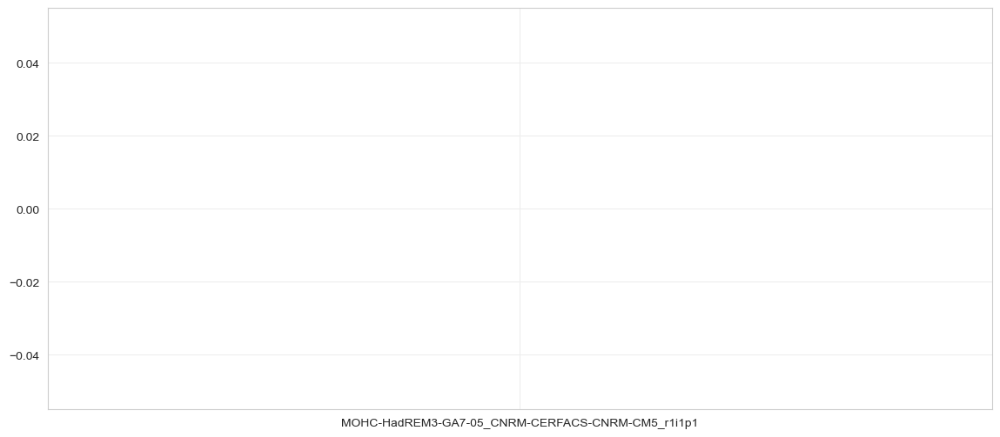

In [21]:
# collect yearly values per climate_model_chain (keys are "{climate_model_chain}_{scenario}")
chain_values = {}
for key, ds in ds_precip_yearly.items():
    chain = key.rsplit("_", 1)[0]  # remove trailing scenario
    if chain.startswith("CNRM-ALADIN63"):
        continue
    # select years 2021-2050 (inclusive)
    da = ds["pr"].sel(time=slice("2021", "2050"))
    # convert to 1D numpy array of values (some models might have missing years -> will be shorter)
    vals = np.asarray(da.values).ravel()
    if vals.size == 0:
        continue
    chain_values.setdefault(chain, []).extend(vals.tolist())

# build DataFrame (columns = chains, unequal lengths filled with NaN)
df_box = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in chain_values.items()]))

# plotting
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=df_box, ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_ylabel("Yearly mean precipitation in mm/day (averaged over CH)")
ax.set_title("Distribution of yearly precipitation (2021-2050) by climate model chain")
plt.tight_layout()
plt.show()

## MRRO

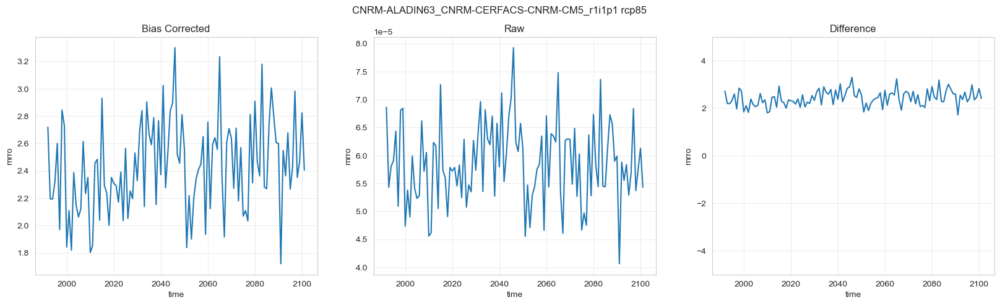

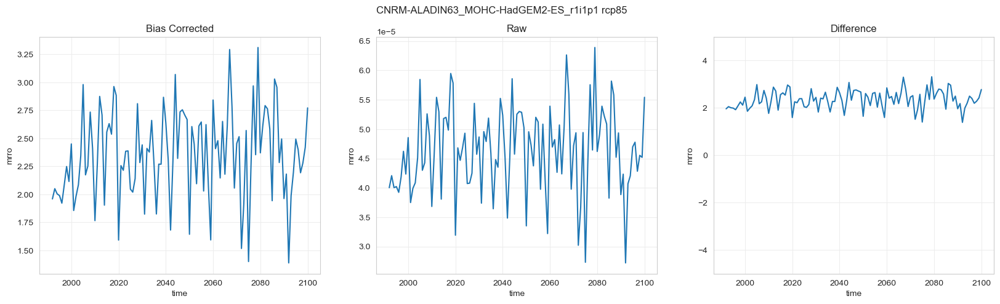

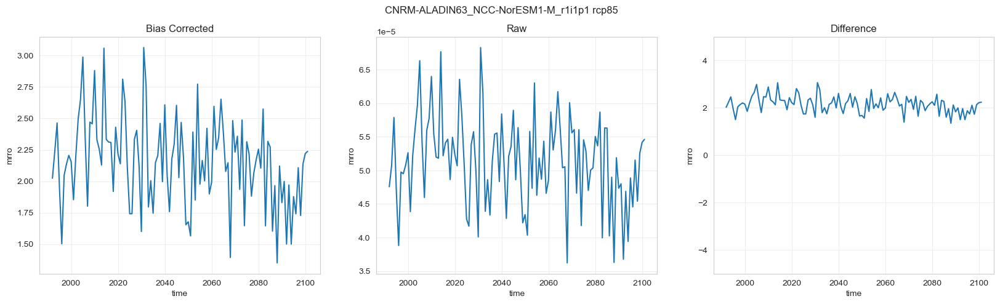

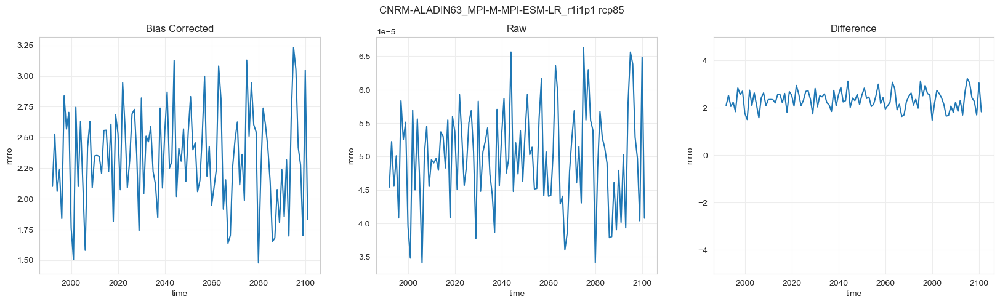

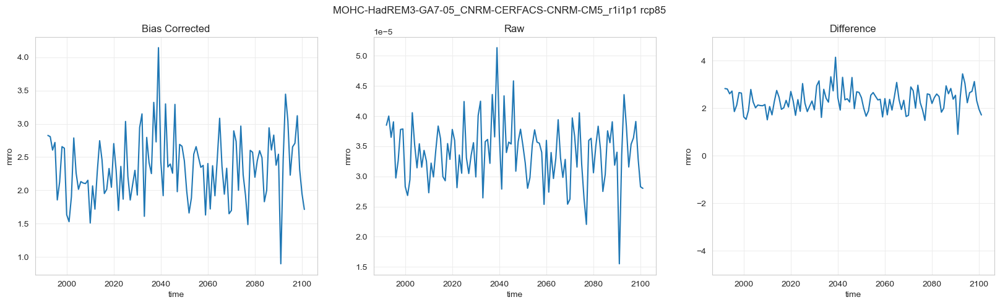

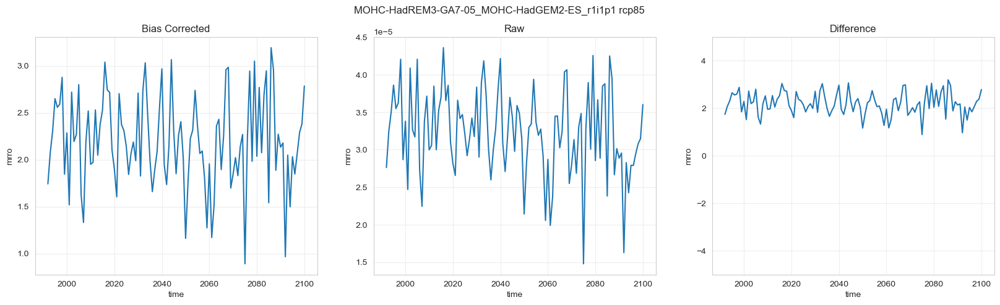

KeyboardInterrupt: 

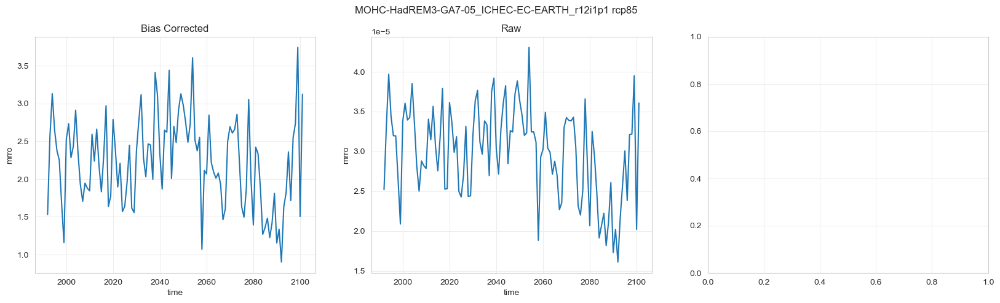

In [9]:
for path in (path_data_processed / "cordex_processed").glob(
    "*rcp85/bias_corrected/day/mrro.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)

    ds_pr_bs = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "day" / "mrro.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).mrro.sel(time=slice("1991-01-01", None)).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])
    ds_pr_raw = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / "day" / "mrro.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).mrro.sel(time=slice("1991-01-01", None)).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"]) * 86400
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f"{climate_model_chain} {climate_scenario}")
    ds_pr_bs.plot(ax=ax[0])
    ax[0].set_title("Bias Corrected")
    ds_pr_raw.plot(ax=ax[1])
    ax[1].set_title("Raw")
    (ds_pr_bs - ds_pr_raw).plot(ax=ax[2])
    ax[2].set_title("Difference")
    ax[2].set_ylim(-5, 5)
    plt.show()

## rsds

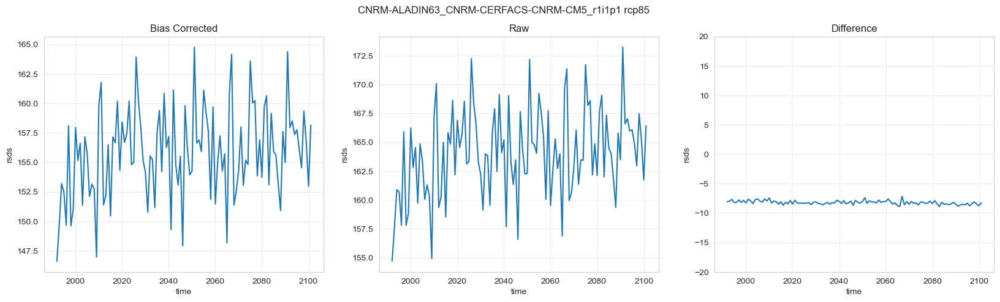

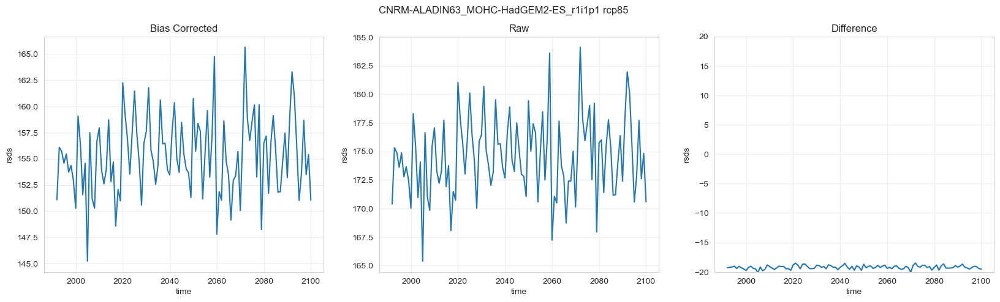

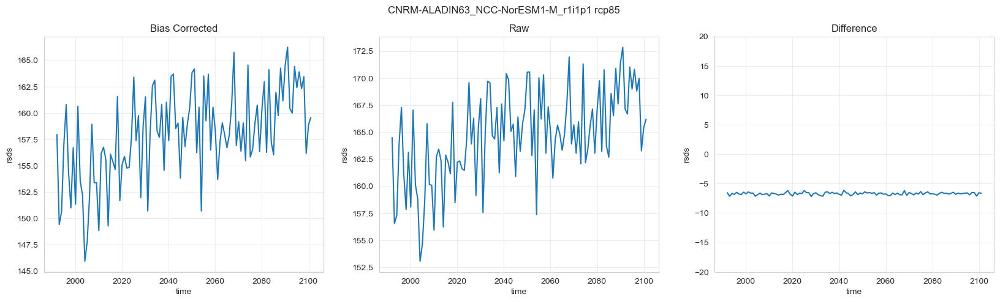

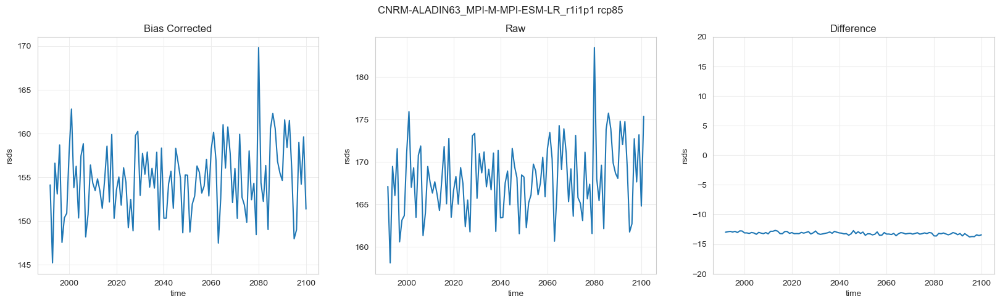

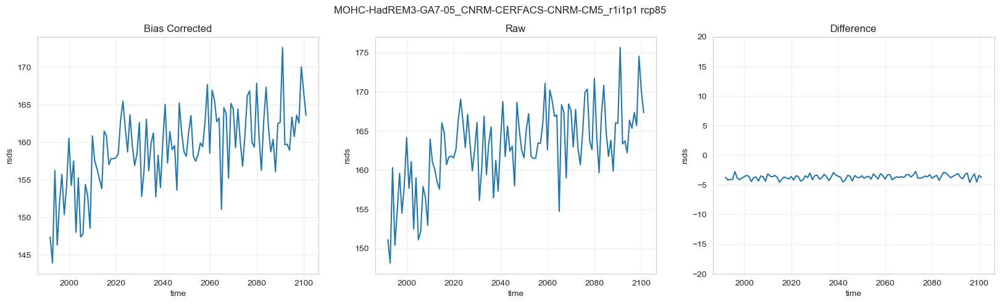

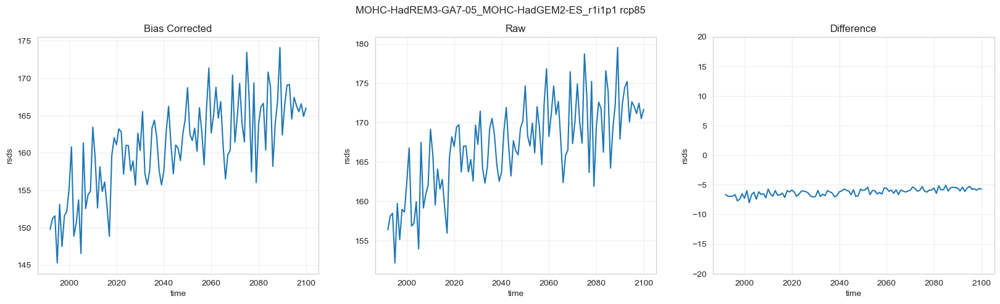

In [38]:
for path in (path_data_processed / "cordex_processed").glob(
    "*rcp85/bias_corrected/3hr/rsds.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)

    ds_pr_bs = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "3hr" / "rsds.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).rsds.sel(time=slice("1991-01-01", None)).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])
    ds_pr_raw = (sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / "3hr" / "rsds.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).rsds.sel(time=slice("1991-01-01", None)).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"]))
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f"{climate_model_chain} {climate_scenario}")
    ds_pr_bs.plot(ax=ax[0])
    ax[0].set_title("Bias Corrected")
    ds_pr_raw.plot(ax=ax[1])
    ax[1].set_title("Raw")
    (ds_pr_bs - ds_pr_raw).plot(ax=ax[2])
    ax[2].set_title("Difference")
    ax[2].set_ylim(-20, 20)
    plt.show()

## Surface Wind

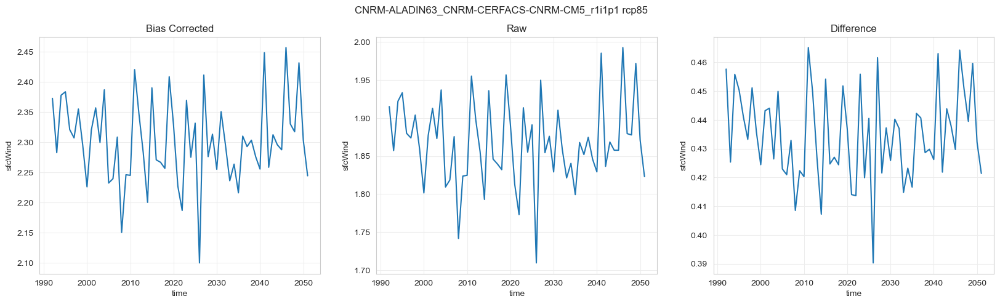

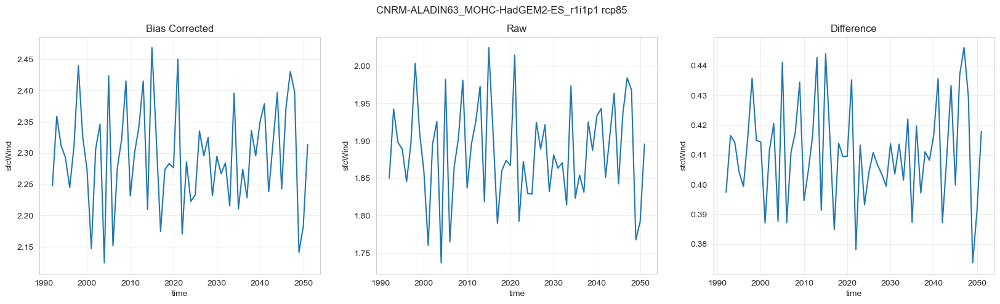

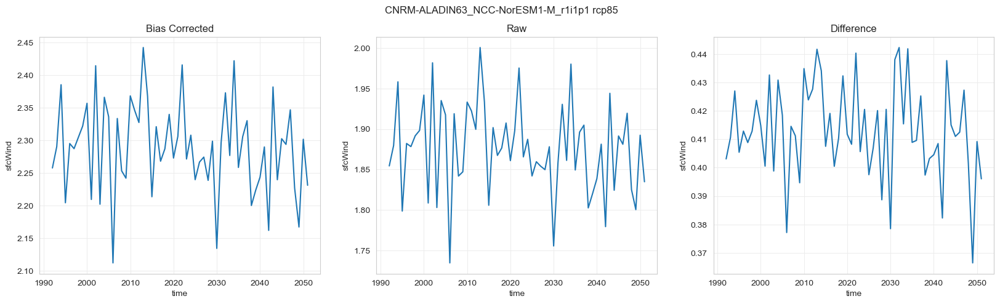

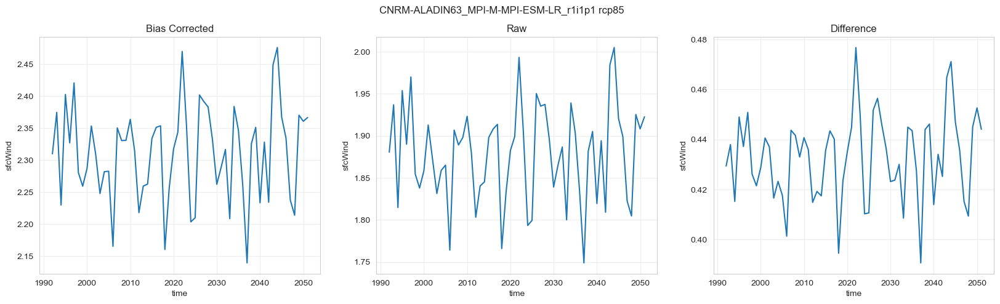

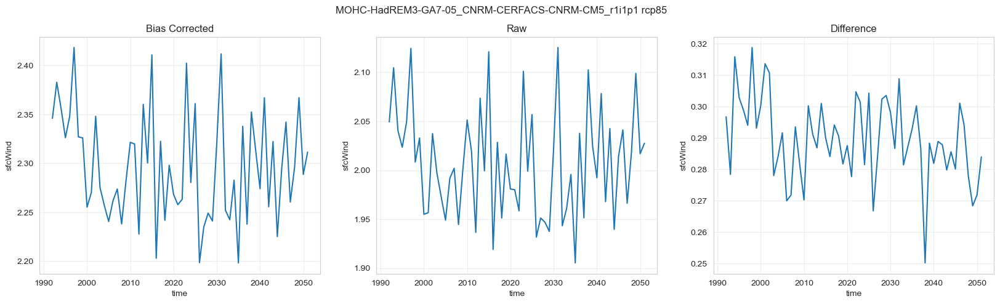

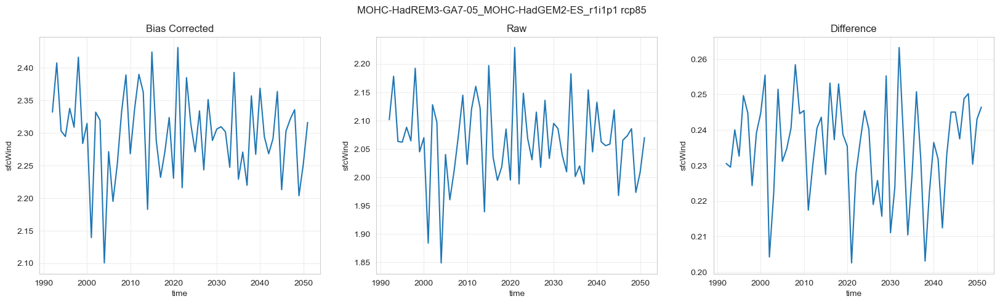

In [10]:
for path in (path_data_processed / "cordex_processed").glob(
    "*rcp85/bias_corrected/3hr/sfcWind.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)

    ds_sfcWind_bs = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "3hr" / "sfcWind.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).sfcWind.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])

    ds_sfcWind_raw = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / "3hr" / "sfcWind.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
    ).sfcWind.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])

    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f"{climate_model_chain} {climate_scenario}")
    ds_sfcWind_bs.plot(ax=ax[0])
    ax[0].set_title("Bias Corrected")
    ds_sfcWind_raw.plot(ax=ax[1])
    ax[1].set_title("Raw")
    (ds_sfcWind_bs - ds_sfcWind_raw).plot(ax=ax[2])
    ax[2].set_title("Difference")
    plt.show()

## PSL

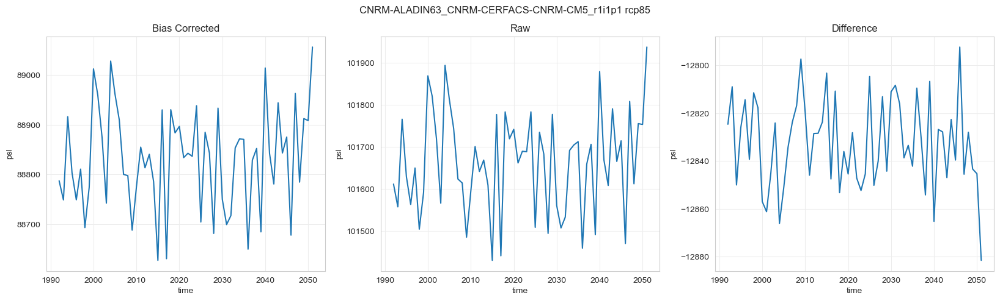

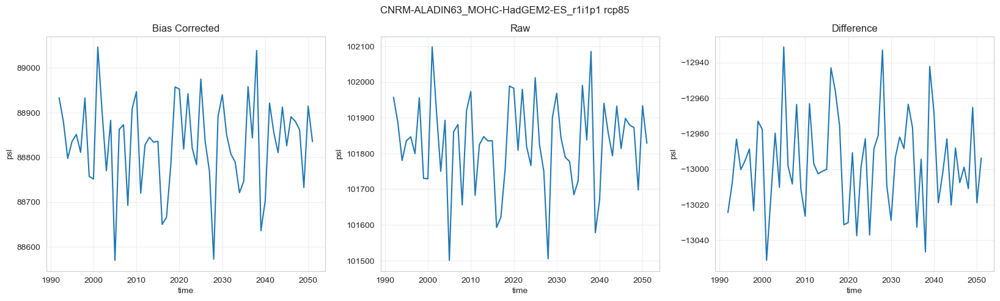

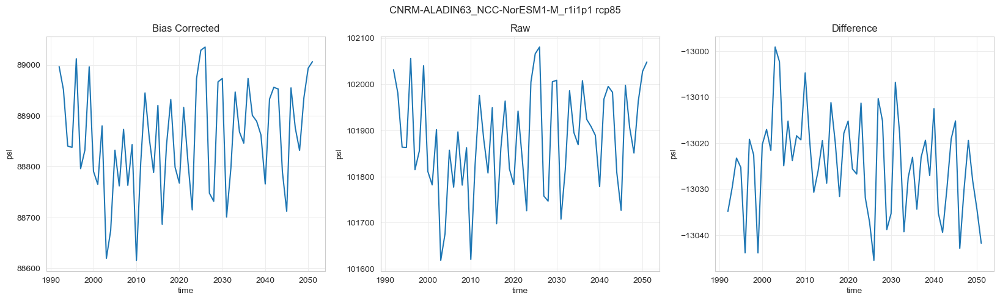

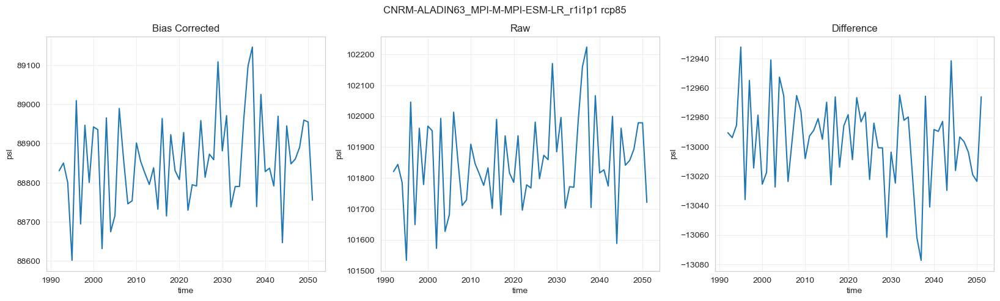

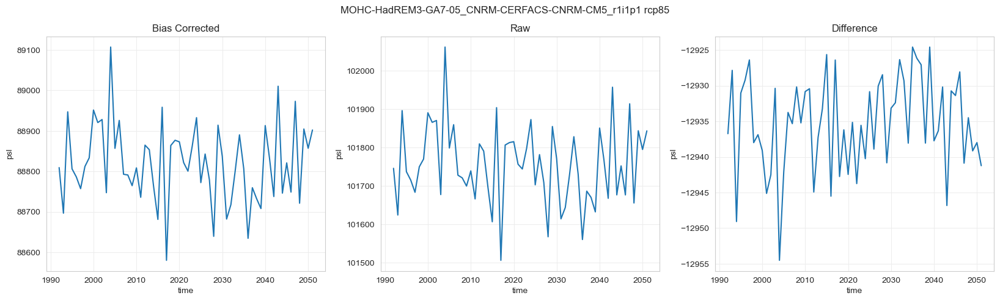

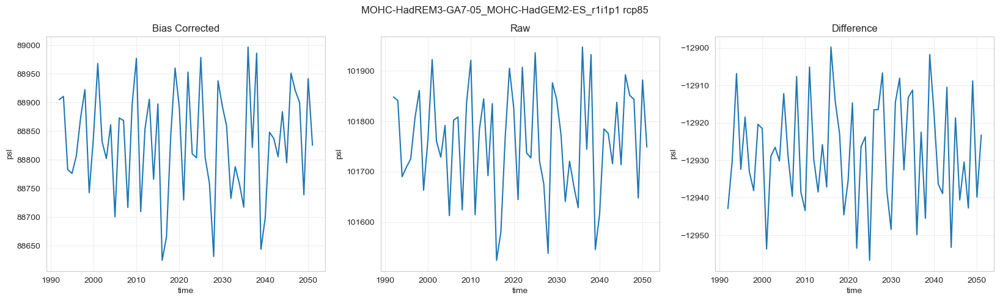

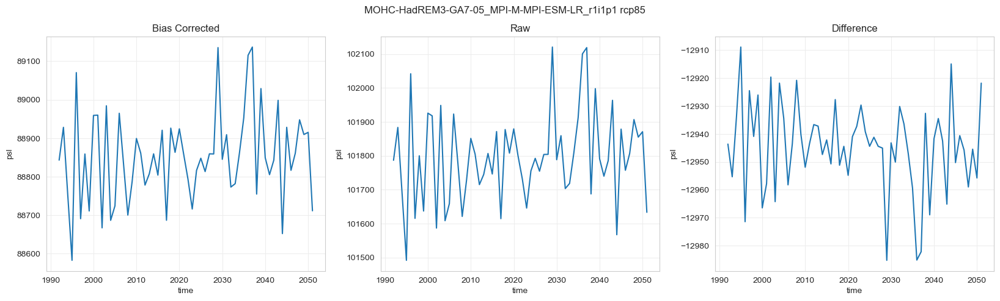

In [11]:
for path in (path_data_processed / "cordex_processed").glob(
    "*rcp85/bias_corrected/3hr/psl.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)

    ds_psl_bs = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "3hr" / "psl.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).psl.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])

    ds_psl_raw = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / "3hr" / "psl.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
    ).psl.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])

    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f"{climate_model_chain} {climate_scenario}")
    ds_psl_bs.plot(ax=ax[0])
    ax[0].set_title("Bias Corrected")
    ds_psl_raw.plot(ax=ax[1])
    ax[1].set_title("Raw")
    (ds_psl_bs - ds_psl_raw).plot(ax=ax[2])
    ax[2].set_title("Difference")
    plt.show()

## hurs

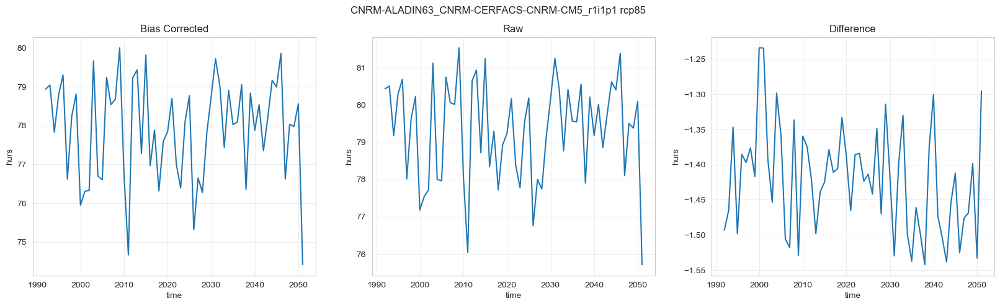

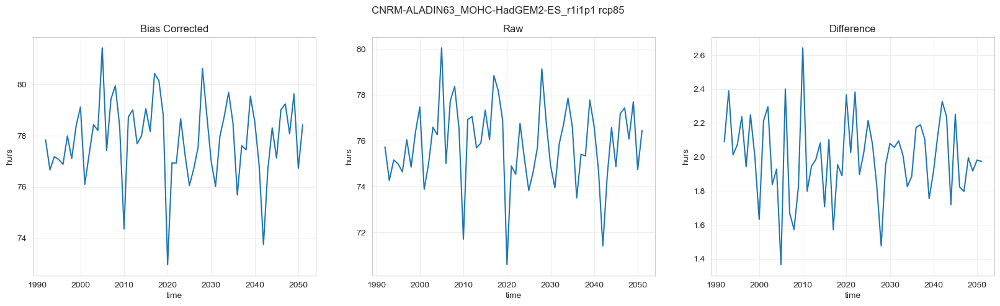

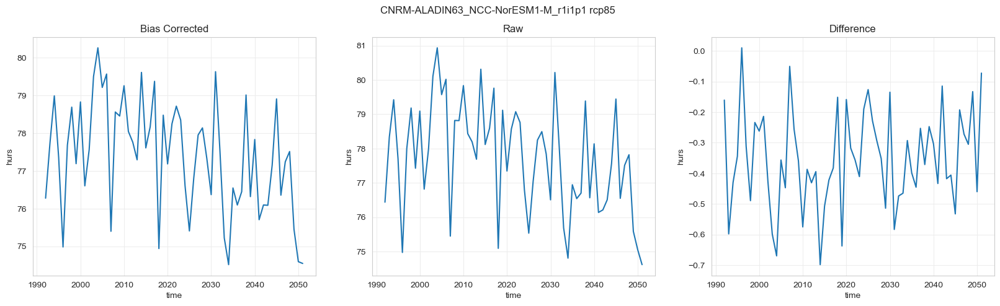

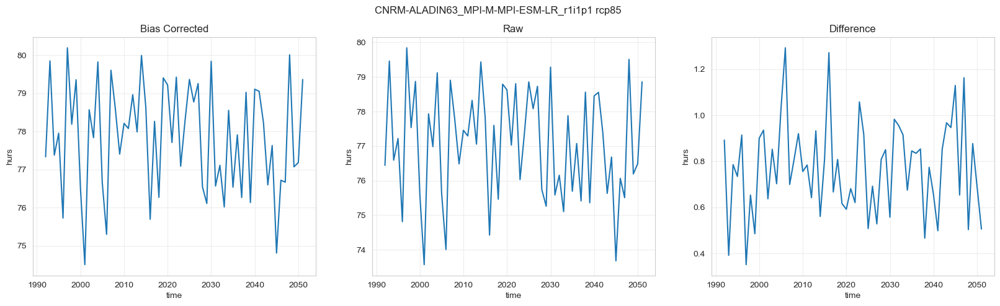

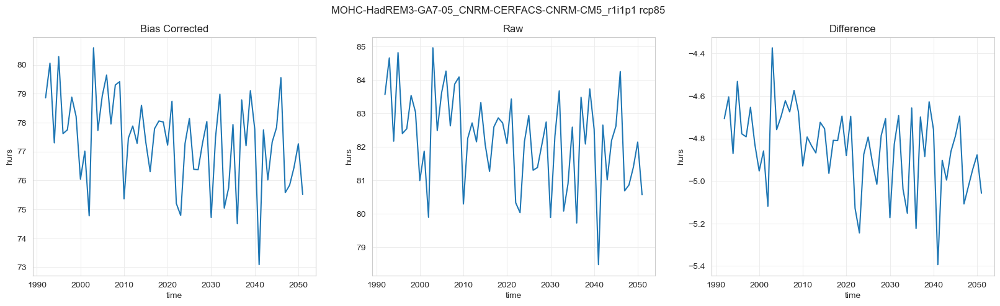

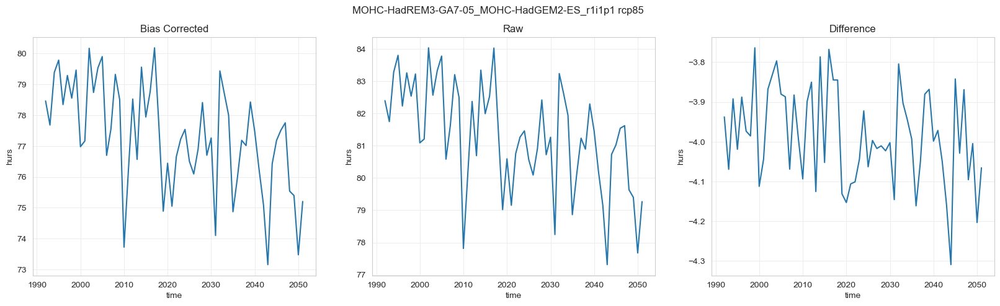

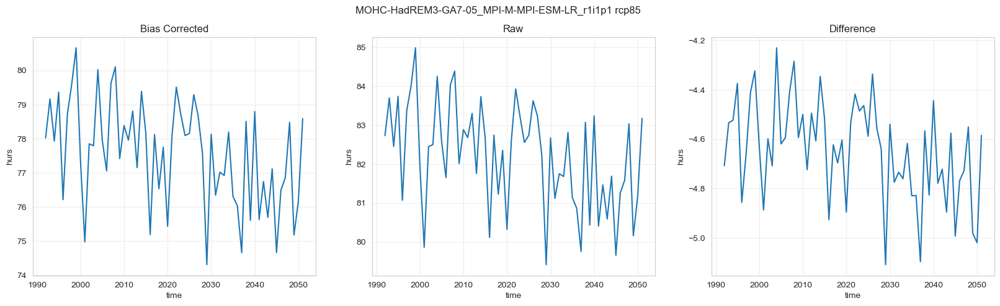

In [12]:
for path in (path_data_processed / "cordex_processed").glob(
    "*rcp85/bias_corrected/3hr/hurs.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)

    ds_hurs_bs = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "bias_corrected" / "3hr" / "hurs.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
        ).hurs.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])

    ds_hurs_raw = sel_extent(
            xr.open_zarr(
                path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / "3hr" / "hurs.zarr",
                chunks="auto",
            ),
            extent=EXTENT_CH,
    ).hurs.sel(time=slice("1991-01-01", "2050-12-31")).resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])

    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f"{climate_model_chain} {climate_scenario}")
    ds_hurs_bs.plot(ax=ax[0])
    ax[0].set_title("Bias Corrected")
    ds_hurs_raw.plot(ax=ax[1])
    ax[1].set_title("Raw")
    (ds_hurs_bs - ds_hurs_raw).plot(ax=ax[2])
    ax[2].set_title("Difference")
    plt.show()

## Comparisons

### Yearly

In [7]:
vars = ["tas", "rsds", "mrro"]
res = {"tas": "3hr", "pr": "day", "rsds": "3hr", "mrro": "day"}

ds_var_bs_yearly = {var: [] for var in vars}
ds_var_raw_yearly = {var: [] for var in vars}

ds_var_bs_yearly_ch = {var: [] for var in vars}
ds_var_raw_yearly_ch = {var: [] for var in vars}

for var in vars:
    print(f"Processing variable: {var}\n")
    for path in (path_data_processed / "cordex_processed").glob(
        f"*/bias_corrected/{res[var]}/{var}.zarr"
    ):
        climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)
        print(f"Model chain: {climate_model_chain}, Scenario: {climate_scenario}")
        for extent in ["CH"]:
            extent_used = EXTENT_BC if extent == "BC" else EXTENT_CH
            with ProgressBar(dt=1):
                ds_bs = (
                    sel_extent(
                        xr.open_zarr(
                            path_data_processed
                            / "cordex_processed"
                            / f"{climate_model_chain}_{climate_scenario}"
                            / "bias_corrected"
                            / f"{res[var]}"
                            / f"{var}.zarr",
                            chunks="auto",
                        ),
                        extent=extent_used,
                    )[var]
                    .sel(time=slice("1991-01-01", None))
                    .resample(time="YE")
                    .mean(dim="time")
                    .mean(dim=["lat", "lon"])
                    .expand_dims(
                        {
                            "climate_model_chain_scenario": [
                                climate_model_chain + "_" + climate_scenario
                            ]
                        }
                    )
                    .compute()
                )

                if extent == "BC":
                    ds_var_bs_yearly[var].append(ds_bs)
                else:
                    ds_var_bs_yearly_ch[var].append(ds_bs)

Processing variable: tas

Model chain: CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1, Scenario: rcp85
[########################################] | 100% Completed | 56.12 s
Model chain: CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1, Scenario: rcp26
[########################################] | 100% Completed | 50.09 s
Model chain: CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1, Scenario: rcp85
[########################################] | 100% Completed | 21.06 s
Model chain: CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1, Scenario: rcp85
[########################################] | 100% Completed | 24.10 s
Model chain: CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1, Scenario: rcp85
[########################################] | 100% Completed | 48.15 s
Model chain: MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1, Scenario: rcp85
[########################################] | 100% Completed | 100.14 s
Model chain: MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1, Scenario: rcp85
[########################################] | 100% Compl

/tmp/ipykernel_47808/2016673066.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_47808/2016673066.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_47808/2016673066.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


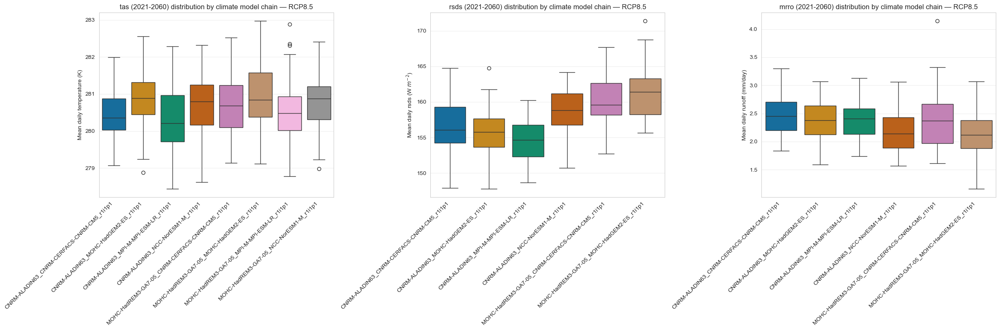

In [20]:
import collections

# use seaborn colorblind palette for all plots
sns.set_palette("colorblind")
ylabels = {
    "pr": "Mean daily precipitation (mm/day)",
    "mrro": "Mean daily runoff (mm/day)",
    "tas": "Mean daily temperature (K)",
    "rsds": "Mean daily rsds (W $m^{-2}$)",
}
fig_width = max(8, 0.5 * max(6, len(df_box.columns)))
fig, axs = plt.subplots(1, 3, figsize=(24, 8))
for i, (var, ds_list) in enumerate(ds_var_bs_yearly_ch.items()):
    ax = axs[i]
    # collect values per model chain (only RCP8.5)
    chain_values = collections.defaultdict(list)
    for ds in ds_list:
        try:
            cmcs = ds["climate_model_chain_scenario"].item()  # e.g. "CNRM-ALADIN63_rcp85"
        except Exception:
            # fallback if .item() fails (array-like)
            cmcs = str(ds["climate_model_chain_scenario"].values[0])
        if not cmcs.lower().endswith("rcp85"):
            continue
        if "ICHEC" in cmcs:
            continue
        chain = cmcs.rsplit("_", 1)[0]
        scenario = cmcs.rsplit("_", 1)[1]
        if scenario != "rcp85":
            continue
        # select 2021-2060 and extract numeric values
        try:
            da = ds.sel(time=slice("2021", "2060"))
            vals = np.asarray(da.values).ravel()
            vals = vals[np.isfinite(vals)]
            if vals.size > 0:
                chain_values[chain].extend(vals.tolist())
        except Exception:
            continue

    if len(chain_values) == 0:
        print(f"No RCP8.5 data for variable '{var}' in 2021-2060 — skipping.")
        continue

    df_box = pd.DataFrame({k: pd.Series(v) for k, v in chain_values.items()})
    df_box = df_box.reindex(sorted(df_box.columns), axis=1)

    sns.boxplot(data=df_box, ax=ax)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_ylabel(ylabels.get(var, var))
    ax.set_title(f"{var} (2021-2060) distribution by climate model chain — RCP8.5")
plt.tight_layout()
plt.show()

### Monthly

In [16]:
# Collect seasonal (DJF, JJA) values per model-chain-scenario for 2021-2060
vars = ["tas", "rsds", "mrro"]
res = {"tas": "3hr", "pr": "day", "rsds": "3hr", "mrro": "day"}

seasons = ["DJF", "JJA"]
# store seasonal results: var -> season -> list of DataArrays (one per model-chain-scenario)
ds_var_bs_seasonal_ch = {var: {s: [] for s in seasons} for var in vars}
ds_var_raw_seasonal_ch = {var: {s: [] for s in seasons} for var in vars}

# helper: compute per-year seasonal means with an end-of-season timestamp
def seasonal_series_per_year(da, season, start_year=2021, end_year=2060):
    tmin = f"{start_year-1}-12-01" if season == "DJF" else f"{start_year}-01-01"
    tmax = f"{end_year}-12-31"
    da_sel = da.sel(time=slice(tmin, tmax))
    months = da_sel["time"].dt.month
    if season == "DJF":
        mask = months.isin([12, 1, 2])
        season_year = xr.where(months == 12, da_sel["time"].dt.year + 1, da_sel["time"].dt.year)
    else:
        mask = months.isin([6, 7, 8])
        season_year = da_sel["time"].dt.year

    da_masked = da_sel.where(mask, drop=True)
    if da_masked.sizes.get("time", 0) == 0:
        return None

    season_year_masked = season_year.sel(time=da_masked["time"]) if "time" in season_year.coords else season_year
    da_masked = da_masked.assign_coords(season_year=("time", season_year_masked.values))
    da_by_season = da_masked.groupby("season_year").mean(dim="time")

    yrs = da_by_season["season_year"].values
    if len(yrs) == 0:
        return None
    if season == "DJF":
        times = [pd.Timestamp(f"{int(y)}-12-31") for y in yrs]
    else:
        times = [pd.Timestamp(f"{int(y)}-08-31") for y in yrs]

    da_by_season = da_by_season.rename({"season_year": "time"})
    da_by_season = da_by_season.assign_coords(time=("time", times))
    da_by_season = da_by_season.sel(time=slice(f"{start_year}-01-01", f"{end_year}-12-31"))
    return da_by_season

for var in vars:
    print(f"Processing variable: {var}\n")
    for path in (path_data_processed / "cordex_processed").glob(f"*/bias_corrected/{res[var]}/{var}.zarr"):
        climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)
        print(f"Model chain: {climate_model_chain}, Scenario: {climate_scenario}")

        extent_used = EXTENT_CH
        with ProgressBar(dt=1):
            ds_bs = (
                sel_extent(
                    xr.open_zarr(
                        path_data_processed
                        / "cordex_processed"
                        / f"{climate_model_chain}_{climate_scenario}"
                        / "bias_corrected"
                        / f"{res[var]}"
                        / f"{var}.zarr",
                        chunks="auto",
                    ),
                    extent=extent_used,
                )[var]
                .sel(time=slice("1991-01-01", None))
            )

            for s in seasons:
                try:
                    da_bs_season = seasonal_series_per_year(ds_bs, s, start_year=2020, end_year=2060)
                    if da_bs_season is not None:
                        da_bs_mean = da_bs_season.mean(dim=["lat", "lon"]).expand_dims({"climate_model_chain_scenario": [climate_model_chain + "_" + climate_scenario]})
                        ds_var_bs_seasonal_ch[var][s].append(da_bs_mean.compute())
                except Exception as e:
                    print(f"Failed bias-corrected seasonal series for {climate_model_chain}_{climate_scenario} {var} {s}: {e}")

print("Finished collecting seasonal series (DJF, JJA) for bias-corrected and raw data.")

Processing variable: tas

Model chain: CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1, Scenario: rcp85
[########################################] | 100% Completed | 87.81 s
[########################################] | 100% Completed | 67.08 s
Model chain: CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1, Scenario: rcp26
[########################################] | 100% Completed | 98.13 s
[########################################] | 100% Completed | 89.13 s
Model chain: CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1, Scenario: rcp85
[########################################] | 100% Completed | 38.05 s
[########################################] | 100% Completed | 78.10 s
Model chain: CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1, Scenario: rcp85
[########################################] | 100% Completed | 115.15 s
[########################################] | 100% Completed | 104.17 s
Model chain: CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1, Scenario: rcp85
[########################################] | 100% Completed | 126.

/tmp/ipykernel_47808/3839402008.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_47808/3839402008.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_47808/3839402008.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


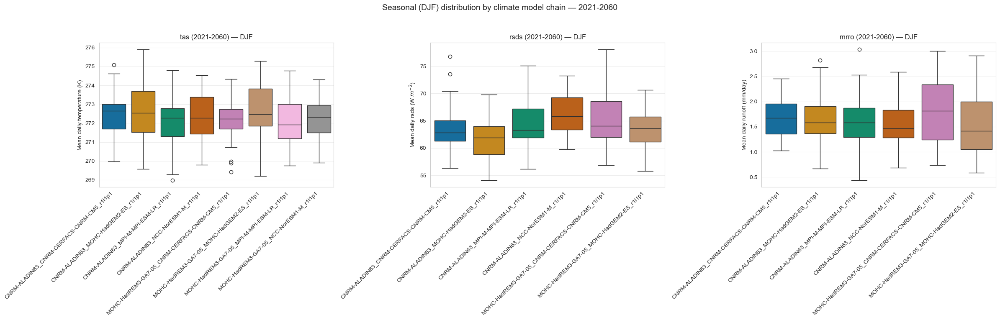

/tmp/ipykernel_47808/3839402008.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_47808/3839402008.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_47808/3839402008.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


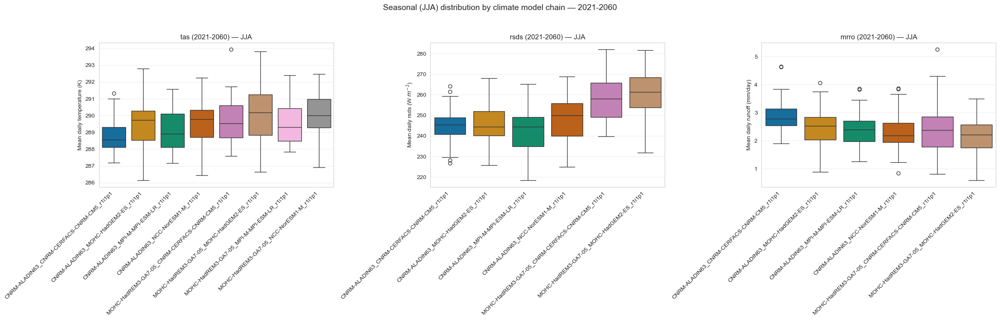

In [19]:
import collections

# Boxplots for seasonal (DJF, JJA) distributions by climate model chain (2021-2060)

for season in seasons:
    fig, axs = plt.subplots(1, len(vars), figsize=(24, 8))
    fig.suptitle(f"Seasonal ({season}) distribution by climate model chain — 2021-2060", fontsize=14)
    for i, var in enumerate(vars):
        ax = axs[i]
        chain_values = collections.defaultdict(list)

        ds_list = ds_var_bs_seasonal_ch.get(var, {}).get(season, [])
        for ds in ds_list:
            try:
                cmcs = ds["climate_model_chain_scenario"].item()
            except Exception:
                cmcs = str(ds["climate_model_chain_scenario"].values[0])

            # only RCP8.5 and skip problematic ensembles as in previous plots
            if not cmcs.lower().endswith("rcp85"):
                continue
            if "ICHEC" in cmcs:
                continue

            chain = cmcs.rsplit("_", 1)[0]
            try:
                da = ds.sel(time=slice("2021", "2060"))
                vals = np.asarray(da.values).ravel()
                vals = vals[np.isfinite(vals)]
                if vals.size > 0:
                    chain_values[chain].extend(vals.tolist())
            except Exception:
                continue

        if len(chain_values) == 0:
            ax.text(0.5, 0.5, "No data", ha="center", va="center")
            ax.set_title(f"{var} — {season}")
            ax.set_ylabel(ylabels.get(var, var))
            ax.set_xticks([])
            continue

        df_box = pd.DataFrame({k: pd.Series(v) for k, v in chain_values.items()})
        df_box = df_box.reindex(sorted(df_box.columns), axis=1)

        sns.boxplot(data=df_box, ax=ax)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
        ax.set_ylabel(ylabels.get(var, var))
        ax.set_title(f"{var} (2021-2060) — {season}")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Raw data

In [113]:
ds_tas_yearly = {}
ds_tas_ref = {}
for path in (path_data_processed / "cordex_processed").glob(
    "*rcp85/regridded/3hr/tas.zarr"
):
    climate_model_chain, climate_scenario = path.parts[-4].rsplit("_", 1)
    print(climate_model_chain, climate_scenario)
    ds_tas = sel_extent(
        xr.open_zarr(
            path,
            chunks="auto",
        ),
        extent=EXTENT_CH,
    )
    with ProgressBar():
        ds_tas_yearly[f"{climate_model_chain}_{climate_scenario}"] = (
            ds_tas.resample(time="YE").mean(dim="time").mean(dim=["lat", "lon"])
        ).compute()
        ds_tas_ref[f"{climate_model_chain}_{climate_scenario}"] = (
            ds_tas_yearly[f"{climate_model_chain}_{climate_scenario}"]
            .sel(time=slice(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1]))
            .mean(dim="time")
            .compute()
        )

CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 rcp85
[########################################] | 100% Completed | 34.91 s
CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1 rcp85
[########################################] | 100% Completed | 27.57 s
CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1 rcp85
[########################################] | 100% Completed | 35.64 s
CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1 rcp85
[########################################] | 100% Completed | 32.09 s
MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1 rcp85
[########################################] | 100% Completed | 26.07 s
MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1 rcp85
[########################################] | 100% Completed | 35.45 s
MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1 rcp85
[########################################] | 100% Completed | 30.05 s
MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1 rcp85
[########################################] | 100% Completed | 33.63 s
MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1 rcp85
[############

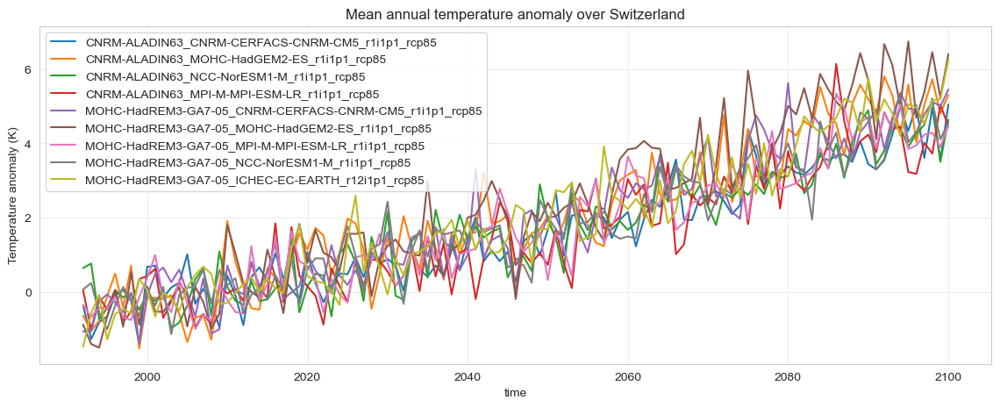

In [115]:
fig, ax = plt.subplots(figsize=(14, 5))
for climate_model_chain_scenario in ds_tas_yearly.keys():
    to_plot = (
        ds_tas_yearly[climate_model_chain_scenario]["tas"].sel(time=slice("1991", "2099"))
        - ds_tas_ref[climate_model_chain_scenario]["tas"]
    )

    to_plot.plot(
        ax=ax,
        label=climate_model_chain_scenario,
    )
ax.set_title("Mean annual temperature anomaly over Switzerland")
ax.set_ylabel("Temperature anomaly (K)")
ax.legend()
plt.show()

In [121]:
# compute 20-year window means centered on each decade center (2030, 2040, ..., 2090)
centers = list(range(2030, 2100, 10))

decade_means = {}
for climate_model_chain_scenario in ds_tas_yearly.keys():
    ds_tas_yearly_model = ds_tas_yearly[climate_model_chain_scenario]
    decade_means_climate_model = []
    for c in centers:
        start = c - 9
        end = c + 10
        da = (
            ds_tas_yearly_model["tas"]
            .sel(time=slice(str(start), str(end)))
            .mean(dim="time")
        )
        da = da.expand_dims(decade_center=[c])
        decade_means_climate_model.append(da)

    decade_means_climate_model = xr.concat(
        decade_means_climate_model, dim="decade_center"
    ).compute()
    decade_means[climate_model_chain_scenario] = decade_means_climate_model

In [122]:
# combine yearly 'tas' from all model-chain-scenario combos into a pandas DataFrame
# then compute the median across models for each year (time index)
series_list = []
for key, ds in decade_means.items():
    s = ds.to_series() - ds_tas_ref[key]["tas"].item()
    s.name = key
    series_list.append(s)

df_decadal = pd.concat(series_list, axis=1)  # index = time, columns = models
median_per_year = df_decadal.median(axis=1, skipna=True)  # pandas Series indexed by time
median_per_year

decade_center
2030    1.025024
2040    1.354553
2050    1.853149
2060    2.334625
2070    3.022369
2080    3.578613
2090    4.129852
dtype: float32

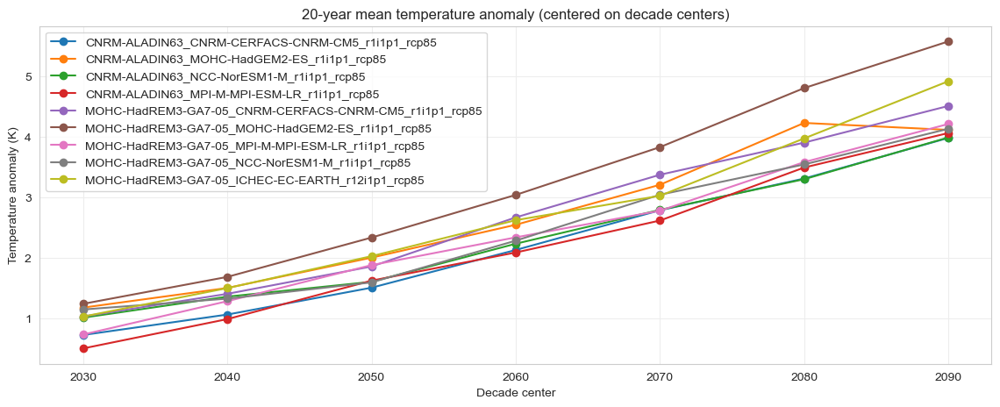

In [118]:
fig, ax = plt.subplots(figsize=(14, 5))

for climate_model_chain_scenario in ds_tas_yearly.keys():
    da = decade_means[climate_model_chain_scenario]  # DataArray with coord 'decade_center'
    ref = ds_tas_ref[climate_model_chain_scenario]["tas"]  # scalar reference mean
    anomaly = (da - ref).compute()  # compute dask array

    ax.plot(
        anomaly["decade_center"].values,
        anomaly.values,
        marker="o",
        label=climate_model_chain_scenario,
    )

ax.set_xticks(centers)
ax.set_xlabel("Decade center")
ax.set_ylabel("Temperature anomaly (K)")
ax.set_title("20-year mean temperature anomaly (centered on decade centers)")
ax.legend()
plt.show()

# Pre-computed statistics

In [ ]:
vars = ["tas", "pr", "rsds", "mrro"]
res = {"tas": "3hr", "pr": "day", "rsds": "3hr", "mrro": "day"}

ds_var_bs_yearly_ch = {var: xr.open_dataset(path_data_processed / "validation" / f"ds_{var}_bs_yearly_ch.nc") for var in vars}
ds_var_bs_seasonal_ch = {var: xr.open_dataset(path_data_processed / "validation" / f"ds_{var}_bs_yearly_season_ch.nc") for var in vars}

In [8]:
tas_anom = (ds_var_bs_yearly_ch["tas"].sel(time=slice("2041", "2060")).mean(dim="time") - ds_var_bs_yearly_ch["tas"].sel(time=slice("1991", "2020")).mean(dim="time"))
tas_anom.sel(climate_model_chain_scenario=tas_anom["climate_model_chain_scenario"].str.contains("rcp85")).tas.to_series().describe()

count    8.000000
mean     1.742363
std      0.232792
min      1.456635
25%      1.606308
50%      1.699875
75%      1.837013
max      2.182587
Name: tas, dtype: float64

## Absolute values

/tmp/ipykernel_14937/3053051890.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/3053051890.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/3053051890.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/3053051890.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


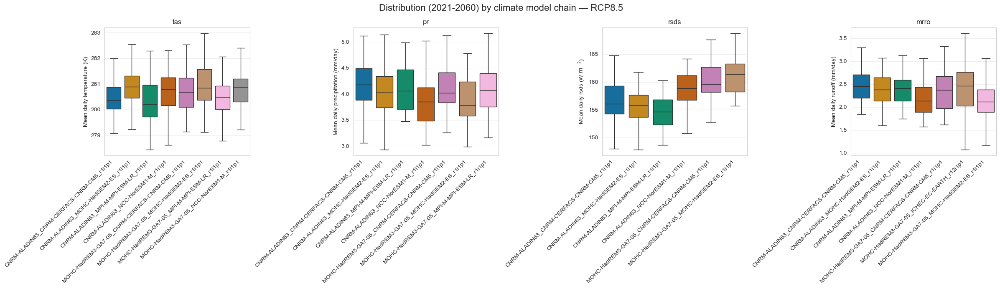

In [34]:
import collections

# use seaborn colorblind palette for all plots
sns.set_palette("colorblind")
ylabels = {
    "pr": "Mean daily precipitation (mm/day)",
    "mrro": "Mean daily runoff (mm/day)",
    "tas": "Mean daily temperature (K)",
    "rsds": "Mean daily rsds (W $m^{-2}$)",
}
fig, axs = plt.subplots(1, len(vars), figsize=(24, 7))
fig.suptitle("Distribution (2021-2060) by climate model chain — RCP8.5", fontsize=16)
for i, (var, ds) in enumerate(ds_var_bs_yearly_ch.items()):
    ax = axs[i]
    # collect values per model chain (only RCP8.5)
    chain_values = collections.defaultdict(list)
    # determine data variable name inside the dataset
    data_var = var if var in ds.data_vars else list(ds.data_vars)[0]

    if "climate_model_chain_scenario" not in ds.coords:
        print(f"No climate_model_chain_scenario coord for var {var} — skipping.")
        continue

    for cmcs in ds["climate_model_chain_scenario"].values:
        cmcs_str = str(cmcs)
        try:
            if not cmcs_str.lower().endswith("rcp85"):
                continue
            # if "ICHEC" in cmcs_str:
            #     continue
            chain, scenario = cmcs_str.rsplit("_", 1)
            if scenario != "rcp85":
                continue
        except Exception:
            continue

        try:
            da = ds[data_var].sel(climate_model_chain_scenario=cmcs).sel(time=slice("2021", "2060"))
            vals = np.asarray(da.values).ravel()
            vals = vals[np.isfinite(vals)]
            if vals.size > 0:
                chain_values[chain].extend(vals.tolist())
        except Exception:
            continue

    if len(chain_values) == 0:
        print(f"No RCP8.5 data for variable '{var}' in 2021-2060 — skipping.")
        continue

    df_box = pd.DataFrame({k: pd.Series(v) for k, v in chain_values.items()})
    df_box = df_box.reindex(sorted(df_box.columns), axis=1)

    sns.boxplot(data=df_box, ax=ax, showfliers=False)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_ylabel(ylabels.get(var, var))
    ax.set_title(f"{var}")
plt.tight_layout()
plt.show()

/tmp/ipykernel_14937/4021517837.py:118: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/4021517837.py:118: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/4021517837.py:118: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/4021517837.py:118: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


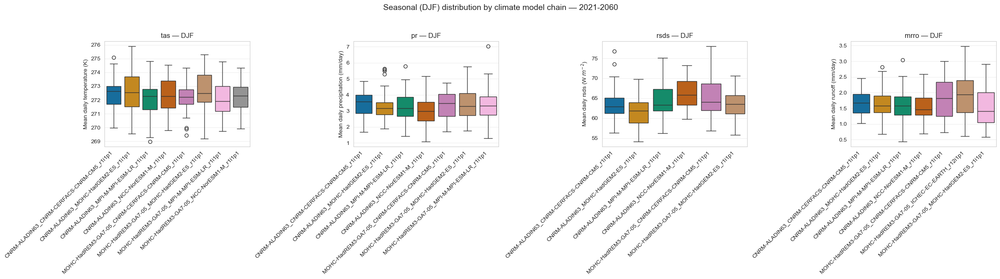

/tmp/ipykernel_14937/4021517837.py:118: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/4021517837.py:118: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/4021517837.py:118: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/4021517837.py:118: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


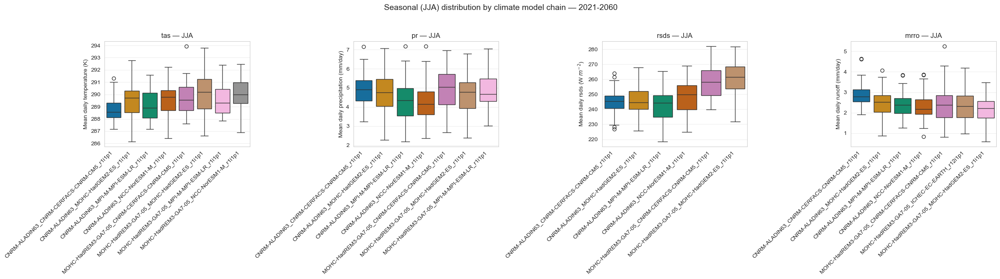

In [35]:
import collections

def _to_time_indexed(da, season):
    # if already has datetime time coord, return as-is
    if "time" in da.coords and np.issubdtype(da["time"].dtype, np.datetime64):
        return da
    # if has numeric season_year coord, convert to appropriate timestamp per season
    if "season_year" in da.coords:
        yrs = da["season_year"].values
        if len(yrs) == 0:
            return None
        if season == "DJF":
            times = [pd.Timestamp(f"{int(y)}-12-31") for y in yrs]
        else:
            times = [pd.Timestamp(f"{int(y)}-08-31") for y in yrs]
        da_new = da.rename({"season_year": "time"})
        da_new = da_new.assign_coords(time=("time", times))
        return da_new
    # fallback: if any coord looks like year numbers, try to coerce
    for c in ("year", "season"):
        if c in da.coords:
            try:
                yrs = da[c].values
                times = [pd.Timestamp(f"{int(y)}-12-31") for y in yrs]
                da_new = da.rename({c: "time"})
                da_new = da_new.assign_coords(time=("time", times))
                return da_new
            except Exception:
                continue
    return None

# Boxplots for seasonal (DJF, JJA) distributions by climate model chain (2021-2060)
for season in ["DJF", "JJA"]:
    fig, axs = plt.subplots(1, len(vars), figsize=(24, 7))
    fig.suptitle(f"Seasonal ({season}) distribution by climate model chain — 2021-2060", fontsize=14)
    for i, var in enumerate(vars):
        ax = axs[i]
        chain_values = collections.defaultdict(list)

        # first try the in-memory collected lists (old style)
        ds_list = ds_var_bs_seasonal_ch.get(var, {}).get(season, [])

        # if empty, try the precomputed dataset with dims (season, climate_model_chain_scenario)
        if (not ds_list) and ("ds_var_bs_seasonal_ch" in globals()):
            ds_all = ds_var_bs_seasonal_ch.get(var)
            if ds_all is not None:
                # pick data variable inside dataset
                data_var = var if var in ds_all.data_vars else list(ds_all.data_vars)[0]
                if "season" in ds_all.coords or "season" in ds_all.dims:
                    try:
                        ds_sel = ds_all.sel(season=season)
                    except Exception:
                        # try to match season strings case-insensitive
                        seasons_available = [str(s) for s in ds_all["season"].values]
                        match = next((s for s in seasons_available if s.upper() == season.upper()), None)
                        if match is not None:
                            ds_sel = ds_all.sel(season=match)
                        else:
                            ds_sel = None
                    if ds_sel is not None:
                        # build a list of DataArrays per climate_model_chain_scenario
                        ds_list = []
                        if "climate_model_chain_scenario" in ds_sel.coords:
                            for cmcs in ds_sel["climate_model_chain_scenario"].values:
                                try:
                                    da = ds_sel[data_var].sel(climate_model_chain_scenario=cmcs)
                                    da_t = _to_time_indexed(da, season)
                                    if da_t is not None:
                                        # attach climate_model_chain_scenario coord if missing
                                        if "climate_model_chain_scenario" not in da_t.coords:
                                            da_t = da_t.expand_dims({"climate_model_chain_scenario": [str(cmcs)]})
                                        ds_list.append(da_t)
                                except Exception:
                                    continue

        # now iterate over ds_list which can be a list of DataArrays (time-indexed)
        for ds in ds_list:
            try:
                # extract climate model chain scenario string
                try:
                    cmcs = ds["climate_model_chain_scenario"].item()
                except Exception:
                    cmcs = str(ds["climate_model_chain_scenario"].values[0])
            except Exception:
                # if no coord, skip
                continue

            # only RCP8.5 and skip problematic ensembles as in previous plots
            if not cmcs.lower().endswith("rcp85"):
                continue
            # if "ICHEC" in cmcs:
            #     continue

            chain = cmcs.rsplit("_", 1)[0]
            try:
                da_time = _to_time_indexed(ds, season)
                if da_time is None:
                    continue
                da_sel = da_time.sel(time=slice("2021", "2060"))
                vals = np.asarray(da_sel.values).ravel()
                vals = vals[np.isfinite(vals)]
                if vals.size > 0:
                    chain_values[chain].extend(vals.tolist())
            except Exception:
                continue

        if len(chain_values) == 0:
            ax.text(0.5, 0.5, "No data", ha="center", va="center")
            ax.set_title(f"{var} — {season}")
            ax.set_ylabel(ylabels.get(var, var))
            ax.set_xticks([])
            continue

        df_box = pd.DataFrame({k: pd.Series(v) for k, v in chain_values.items()})
        df_box = df_box.reindex(sorted(df_box.columns), axis=1)

        sns.boxplot(data=df_box, ax=ax)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
        ax.set_ylabel(ylabels.get(var, var))
        ax.set_title(f"{var} — {season}")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

## Relative difference (Future-Reference)

/tmp/ipykernel_19398/3573025763.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_19398/3573025763.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_19398/3573025763.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


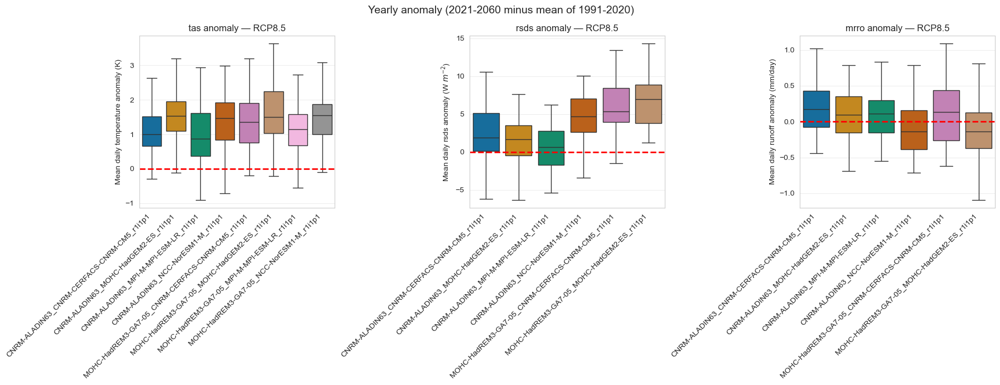

In [13]:
import collections

# compute future (2021-2060) minus reference (1991-2020) anomalies per climate model chain
ylabels = {
    "pr": "Mean daily precipitation anomaly (mm/day)",
    "mrro": "Mean daily runoff anomaly (mm/day)",
    "tas": "Mean daily temperature anomaly (K)",
    "rsds": "Mean daily rsds anomaly (W $m^{-2}$)",
}
sns.set_palette("colorblind")
fig, axs = plt.subplots(1, len(vars), figsize=(len(vars) * 6, 7))
fig.suptitle("Yearly anomaly (2021-2060 minus mean of 1991-2020)", fontsize=14)
for i, var in enumerate(vars):
    ax = axs[i]
    ds = ds_var_bs_yearly_ch.get(var)
    if ds is None:
        ax.text(0.5, 0.5, "No data", ha="center", va="center")
        ax.set_title(var)
        continue

    # pick the data variable name inside the dataset
    data_var = var if var in ds.data_vars else list(ds.data_vars)[0]

    chain_values = collections.defaultdict(list)

    if "climate_model_chain_scenario" not in ds.coords:
        ax.text(0.5, 0.5, "No climate_model_chain_scenario coord", ha="center", va="center")
        ax.set_title(var)
        continue

    for cmcs in ds["climate_model_chain_scenario"].values:
        cmcs_str = str(cmcs)
        if not cmcs_str.lower().endswith("rcp85"):
            continue
        if "ICHEC" in cmcs_str:
            continue
        try:
            # select future and reference periods and average over time
            da_future = ds[data_var].sel(climate_model_chain_scenario=cmcs).sel(time=slice("2021", "2060"))
            da_ref = ds[data_var].sel(climate_model_chain_scenario=cmcs).sel(time=slice("1991", "2020"))

            if da_future.sizes.get("time", 0) == 0 or da_ref.sizes.get("time", 0) == 0:
                continue

            val_future_arr = np.asarray(da_future.values).ravel()
            val_ref = float(da_ref.mean(dim="time").values)
            anomalies = val_future_arr - val_ref
            # keep only finite values and add them to the chain list
            anoms = anomalies[np.isfinite(anomalies)]
            chain = cmcs_str.rsplit("_", 1)[0]
            chain_values[chain].extend(anoms.tolist())

        except Exception:
            continue

    if len(chain_values) == 0:
        ax.text(0.5, 0.5, "No RCP8.5 data (2021-2060)", ha="center", va="center")
        ax.set_title(var)
        continue

    df_box = pd.DataFrame({k: pd.Series(v) for k, v in chain_values.items()})
    df_box = df_box.reindex(sorted(df_box.columns), axis=1)

    sns.boxplot(data=df_box, ax=ax, showfliers=False)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_ylabel(ylabels.get(var, var))
    ax.set_title(f"{var} anomaly — RCP8.5")
    ax.axhline(0, color="red", linestyle="--", linewidth=2)

plt.tight_layout()
plt.show()

/tmp/ipykernel_14937/85899868.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/85899868.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/85899868.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/85899868.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


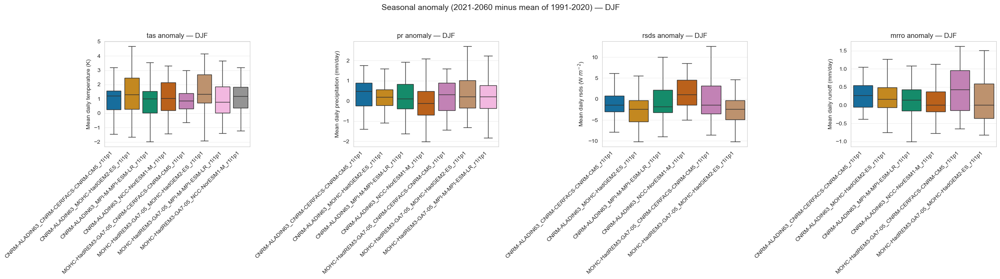

/tmp/ipykernel_14937/85899868.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/85899868.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/85899868.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/tmp/ipykernel_14937/85899868.py:101: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


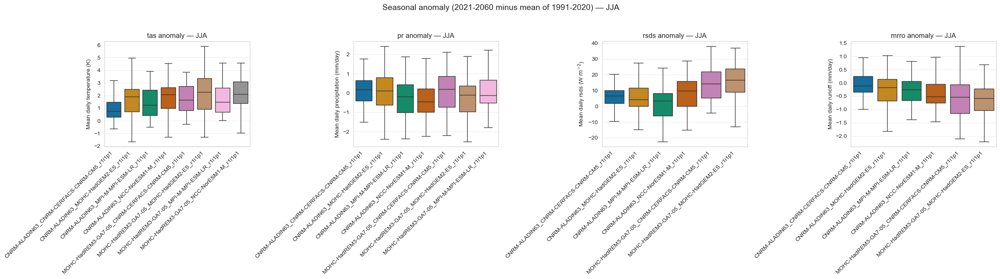

In [30]:
import collections

# seasonal (2021-2060 minus 1991-2020) anomalies by climate model chain — DJF & JJA

seasons = ["DJF", "JJA"]
sns.set_palette("colorblind")

for season in seasons:
    fig, axs = plt.subplots(1, len(vars), figsize=(24, 7))
    fig.suptitle(f"Seasonal anomaly (2021-2060 minus mean of 1991-2020) — {season}", fontsize=14)

    for i, var in enumerate(vars):
        ax = axs[i]
        chain_values = collections.defaultdict(list)

        # try in-memory collected lists first
        ds_list = []
        try:
            ds_list = ds_var_bs_seasonal_ch.get(var, {}).get(season, []) or []
        except Exception:
            ds_list = []

        # fallback to precomputed dataset if list is empty
        if (not ds_list) and ("ds_var_bs_seasonly_ch" in globals() or "ds_var_bs_seasonal_ch" in globals()):
            # try both common names
            ds_all = None
            if "ds_var_bs_seasonly_ch" in globals():
                ds_all = ds_var_bs_seasonal_ch.get(var)
            if ds_all is None and "ds_var_bs_seasonal_ch" in globals():
                # this may be the precomputed dataset dict loaded from files
                if isinstance(ds_var_bs_seasonal_ch.get(var), xr.Dataset):
                    ds_all = ds_var_bs_seasonal_ch.get(var)

            if ds_all is not None:
                data_var = var if var in ds_all.data_vars else list(ds_all.data_vars)[0]
                # select season inside dataset if available
                try:
                    ds_sel = ds_all.sel(season=season)
                except Exception:
                    seasons_available = [str(s) for s in ds_all["season"].values] if "season" in ds_all.coords else []
                    match = next((s for s in seasons_available if s.upper() == season.upper()), None)
                    ds_sel = ds_all.sel(season=match) if match is not None else None

                if ds_sel is not None and "climate_model_chain_scenario" in ds_sel.coords:
                    for cmcs in ds_sel["climate_model_chain_scenario"].values:
                        try:
                            da = ds_sel[data_var].sel(climate_model_chain_scenario=cmcs)
                            da_t = _to_time_indexed(da, season)
                            if da_t is not None:
                                # ensure climate_model_chain_scenario coord present
                                if "climate_model_chain_scenario" not in da_t.coords:
                                    da_t = da_t.expand_dims({"climate_model_chain_scenario": [str(cmcs)]})
                                ds_list.append(da_t)
                        except Exception:
                            continue

        # iterate datasets/arrays and compute anomalies
        for ds in ds_list:
            try:
                cmcs = None
                try:
                    cmcs = ds["climate_model_chain_scenario"].item()
                except Exception:
                    cmcs = str(ds["climate_model_chain_scenario"].values[0])
                if not cmcs.lower().endswith("rcp85"):
                    continue
                if "ICHEC" in cmcs:
                    continue
                chain = cmcs.rsplit("_", 1)[0]

                da_time = _to_time_indexed(ds, season)
                if da_time is None:
                    continue

                da_future = da_time.sel(time=slice("2021", "2060"))
                da_ref = da_time.sel(time=slice("1991", "2020"))

                if da_future.sizes.get("time", 0) == 0 or da_ref.sizes.get("time", 0) == 0:
                    continue

                val_future_arr = np.asarray(da_future.values).ravel()
                val_ref = float(da_ref.mean(dim="time").values)
                anomalies = val_future_arr - val_ref
                anoms = anomalies[np.isfinite(anomalies)]
                if anoms.size > 0:
                    chain_values[chain].extend(anoms.tolist())
            except Exception:
                continue

        if len(chain_values) == 0:
            ax.text(0.5, 0.5, "No data", ha="center", va="center")
            ax.set_title(f"{var} — {season}")
            ax.set_ylabel(ylabels.get(var, var))
            ax.set_xticks([])
            continue

        df_box = pd.DataFrame({k: pd.Series(v) for k, v in chain_values.items()})
        df_box = df_box.reindex(sorted(df_box.columns), axis=1)

        sns.boxplot(data=df_box, ax=ax, showfliers=False)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
        ax.set_ylabel(ylabels.get(var, var))
        ax.set_title(f"{var} anomaly — {season}")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()